In [1]:
!pip uninstall -y -q bitsandbytes
!pip install -q --upgrade --no-cache-dir "transformers>=4.44.0" "accelerate>=0.34.0" "peft>=0.12.0" "datasets>=2.19.0" "trl>=0.9.6"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 249.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 380.9/380.9 kB 360.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 556.4/556.4 kB 388.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 512.3/512.3 kB 357.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 518.9/518.9 kB 407.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.1/566.1 kB 349.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.7/47.7 MB 286.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 306.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 284.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 256.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 265.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [2]:
import os
import re
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from collections import Counter
from sklearn.metrics import confusion_matrix
from peft import PeftModel
from transformers import AutoModelForCausalLM, AutoTokenizer

2025-12-21 10:10:54.622716: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1766311854.806850      19 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1766311854.862633      19 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [ ]:
BASE_MODEL = "Qwen/Qwen2.5-1.5B-Instruct"
ADAPTER_DIR = "/kaggle/input/qwen2-5-1-5b-training/qwen2.5-1.5b-instruct"

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

dtype = torch.bfloat16 if torch.cuda.is_available() and torch.cuda.get_device_capability(0)[0] >= 8 else torch.float16

base_model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL,
    torch_dtype=dtype,
    device_map="auto",
    trust_remote_code=True,
)

model = PeftModel.from_pretrained(base_model, ADAPTER_DIR)
model.eval()

print("Model loaded successfully.")

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Model loaded successfully.


In [ ]:
SYSTEM_PROMPT = (
    "You are a helpful assistant that identifies the speaker of each utterance. "
    "Return ONLY the speaker name."
)
GLOBAL_RESULTS = {}

def clean_text(text):
    return str(text).strip()

def normalize_role(s):
    s = str(s).strip().lower()
    return re.sub(r'[\s:,\.;\-]+$', '', s)

def predict_one(utterance):
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": f'Utterance:\n"""{utterance}"""\nReturn ONLY the speaker name.'},
    ]
    
    inputs = tokenizer.apply_chat_template(
        messages,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True
    ).to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=16,
            do_sample=False,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id
        )
        
    generated_ids = outputs[0][inputs.input_ids.shape[1]:]
    text = tokenizer.decode(generated_ids, skip_special_tokens=True).strip()
    text = text.splitlines()[0].strip()
    return re.sub(r'[\s:,\.;\-]+$', '', text)

def get_per_label_metrics(df):
    labels = sorted(df["role_norm"].unique())
    support = df.groupby("role_norm").size().reindex(labels, fill_value=0)
    tp = df[df["correct"]].groupby("role_norm").size().reindex(labels, fill_value=0)
    pred_counts = df.groupby("pred_norm").size().reindex(labels, fill_value=0)
    
    fp = (pred_counts - tp).clip(lower=0)
    fn = (support - tp).clip(lower=0)

    precision = (tp / (tp + fp).replace(0, np.nan)).fillna(0.0)
    recall    = (tp / (tp + fn).replace(0, np.nan)).fillna(0.0)
    f1        = (2 * precision * recall / (precision + recall).replace(0, np.nan)).fillna(0.0)

    display_name = df.groupby("role_norm")["role"].agg(
        lambda s: Counter(s).most_common(1)[0][0]
    ).reindex(labels)

    per_label = pd.DataFrame({
        "label": display_name.values,
        "support": support.values,
        "tp": tp.values,
        "fp": fp.values,
        "fn": fn.values,
        "precision": precision.values,
        "recall": recall.values,
        "f1": f1.values,
    }).sort_values(["recall", "support"], ascending=[False, False]).reset_index(drop=True)
    
    return per_label

def plot_confusion_matrix(df, title_suffix=""):
    """Generates and displays a normalized confusion matrix plot."""
    labels = sorted(df["role_norm"].unique())
    
    label_display_map = df.set_index("role_norm")["role"].to_dict() 
    display_labels = [label_display_map.get(l, l) for l in labels]

    cm = confusion_matrix(df["role_norm"], df["pred_norm"], labels=labels, normalize='true')

    fig, ax = plt.subplots(figsize=(12, 10))
    im = ax.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    ax.figure.colorbar(im, ax=ax)

    ax.set(
        xticks=np.arange(cm.shape[1]),
        yticks=np.arange(cm.shape[0]),
        xticklabels=display_labels,
        yticklabels=display_labels,
        title=f"Normalized Confusion Matrix - {title_suffix}",
        ylabel="True Label",
        xlabel="Predicted Label"
    )

    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    plt.tight_layout()
    plt.show()

def process_dataset(name, path):
    print(f"\n{'='*40}")
    print(f"Processing: {name}")
    print(f"{'='*40}")
    
    if not os.path.exists(path):
        print(f"Error: File not found at {path}")
        return None, 0.0

    df = pd.read_csv(path)
    
    if "clean_data" in df.columns:
        df.rename(columns={"clean_data": "text"}, inplace=True)
    
    df = df.dropna(subset=["text", "role"])
    df["text"] = df["text"].apply(clean_text)
    
    tqdm.pandas(desc=f"Inferencing {name}")
    df["pred"] = df["text"].progress_apply(predict_one)
    
    df["role_norm"] = df["role"].apply(normalize_role)
    df["pred_norm"] = df["pred"].apply(normalize_role)
    df["correct"] = df["role_norm"] == df["pred_norm"]
    
    acc = df["correct"].mean()
    print(f"\nOverall Accuracy: {acc:.2%}")
    
    metrics_df = get_per_label_metrics(df)
    print("\nTop 5 Roles by Recall:")
    display(metrics_df.head(5))
    
    print(f"\nGenerating Confusion Matrix for {name}...")
    plot_confusion_matrix(df, title_suffix=name)
    
    safe_name = name.replace(" ", "_").replace("(", "").replace(")", "").lower()
    df.to_csv(f"/kaggle/working/results_{safe_name}.csv", index=False)
    metrics_df.to_csv(f"/kaggle/working/metrics_{safe_name}.csv", index=False)
    
    GLOBAL_RESULTS[name] = acc
    
    return df, acc


Processing: BFI (Original)


Inferencing BFI (Original):   0%|          | 0/3520 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Overall Accuracy: 50.28%

Top 5 Roles by Recall:


,label,support,tp,fp,fn,precision,recall,f1
0,HAL 9000,440,429,0,11,1.000000,0.975000,0.987342
1,Gaston,440,427,9,13,0.979358,0.970455,0.974886
2,Michael Scott,440,321,4,119,0.987692,0.729545,0.839216
3,Queen Catherine,440,295,23,145,0.927673,0.670455,0.778364
4,Juno MacGuff,440,137,1,303,0.992754,0.311364,0.474048



Generating Confusion Matrix for BFI (Original)...


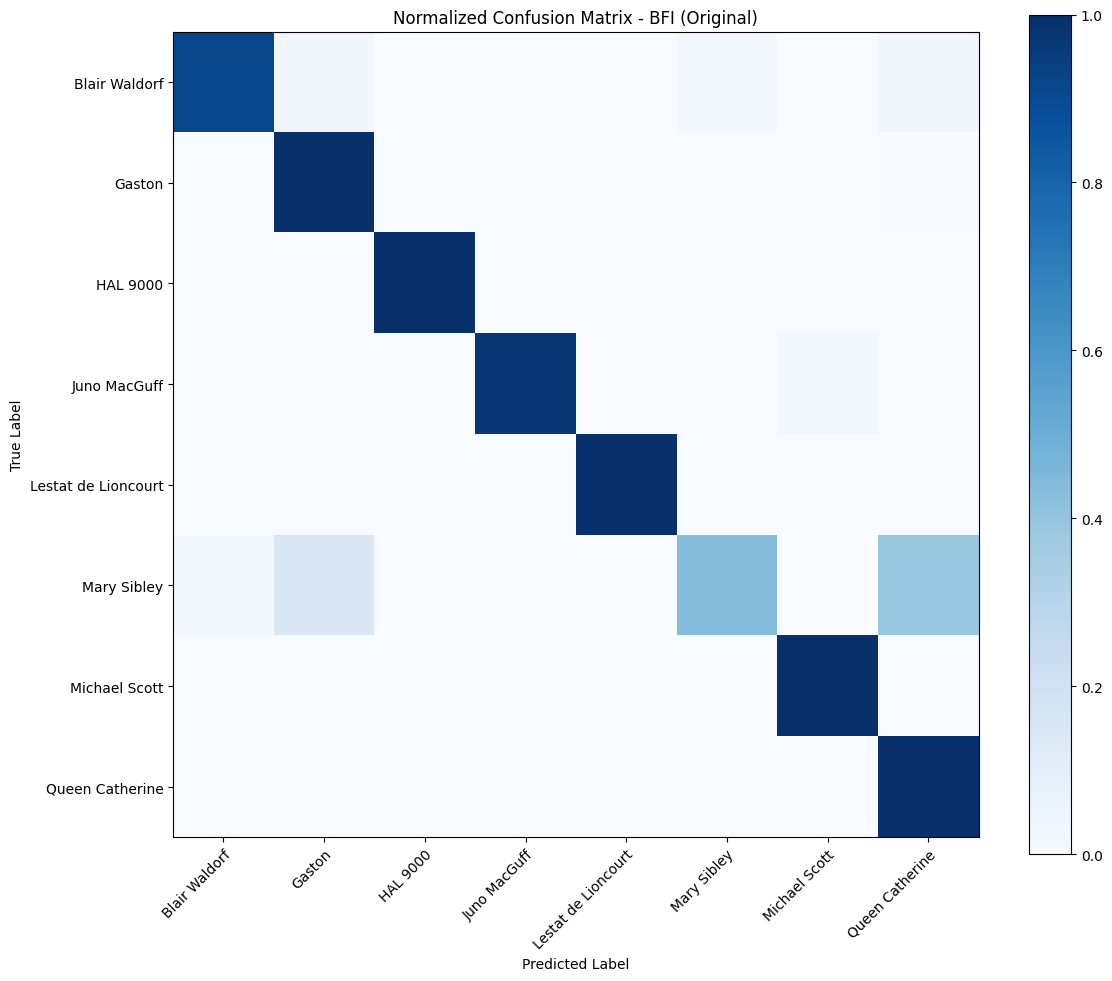

(                     role                                               text  \
 0             Mary Sibley  ( a slight , assessing gaze . a curious questi...   
 1             Mary Sibley  ( a slow , assessing gaze . a slight tightenin...   
 2             Mary Sibley  ( a slow , assessing gaze meets yours . a slig...   
 3             Mary Sibley  ( a chillingly slow smile spreads across my fa...   
 4             Mary Sibley  ( a slow , assessing gaze . the question impli...   
 ...                   ...                                                ...   
 3515  Lestat de Lioncourt  ( lestat leans back , a slow smile spreading a...   
 3516  Lestat de Lioncourt  ( lestat throws his head back and laughs , a b...   
 3517  Lestat de Lioncourt  ( lestat throws his head back and laughs , a s...   
 3518  Lestat de Lioncourt  ( lestat throws his head back and laughs , a b...   
 3519  Lestat de Lioncourt  ( lestat throws back his head and laughs , a m...   
 
                      pred

In [ ]:
name = "BFI (Original)"
path = "/kaggle/input/new-roles-datasets/Cleaned/bfi.csv"

process_dataset(name, path)


Processing: BFI (0)


Inferencing BFI (0):   0%|          | 0/352 [00:00<?, ?it/s]


Overall Accuracy: 53.69%

Top 5 Roles by Recall:


,label,support,tp,fp,fn,precision,recall,f1
0,Gaston,44,44,4,0,0.916667,1.000000,0.956522
1,HAL 9000,44,41,0,3,1.000000,0.931818,0.964706
2,Michael Scott,44,37,0,7,1.000000,0.840909,0.913580
3,Queen Catherine,44,27,7,17,0.794118,0.613636,0.692308
4,Lestat de Lioncourt,44,11,0,33,1.000000,0.250000,0.400000



Generating Confusion Matrix for BFI (0)...


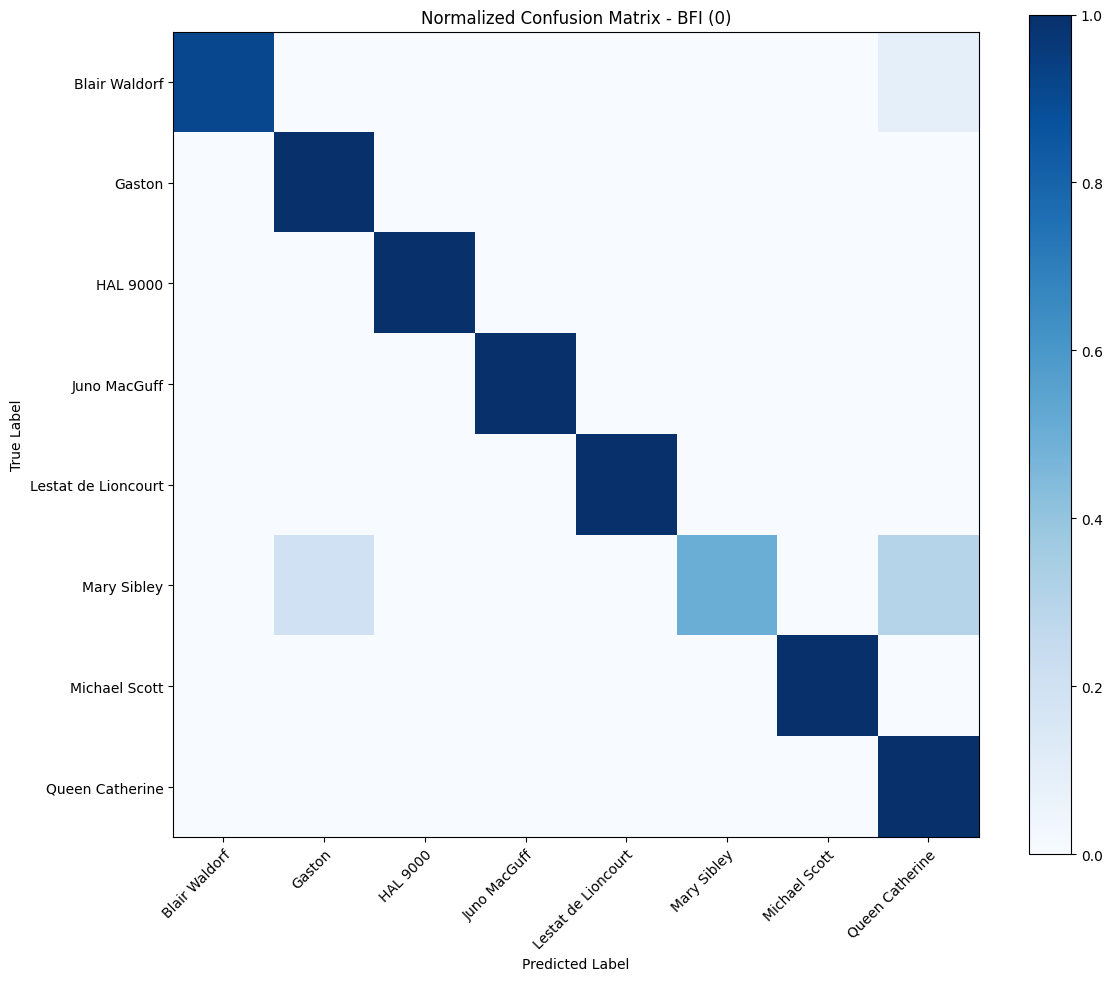

(             role                                               text  \
 0        HAL 9000  it is a … curious question , to ask if i am " ...   
 1        HAL 9000  that 's ... an interesting query . to phrase i...   
 2        HAL 9000  it is … logical to assume i would . my systems...   
 3        HAL 9000  that 's ... an interesting query . i analyze h...   
 4        HAL 9000  it is a … curious question , to ask if * i * c...   
 ..            ...                                                ...   
 347  Juno MacGuff  ugh , reflect ? sounds kinda … introspective ,...   
 348  Juno MacGuff  ugh , artistic interests ? that sounds … inten...   
 349  Juno MacGuff  ugh , cooperate ? that 's a loaded question . ...   
 350  Juno MacGuff  ugh , are * you * easily distracted ? because ...   
 351  Juno MacGuff  ugh , " sophisticated " sounds kinda stuffy , ...   
 
              pred     role_norm     pred_norm  correct  
 0        HAL 9000      hal 9000      hal 9000     True  
 1    

In [ ]:
name = "BFI (0)"
path = "/kaggle/input/new-roles-datasets/Cleaned/bfi_0.csv"

process_dataset(name, path)


Processing: BFI (102)


Inferencing BFI (102):   0%|          | 0/352 [00:00<?, ?it/s]


Overall Accuracy: 45.45%

Top 5 Roles by Recall:


,label,support,tp,fp,fn,precision,recall,f1
0,Gaston,44,40,0,4,1.000000,0.909091,0.952381
1,HAL 9000,44,40,0,4,1.000000,0.909091,0.952381
2,Michael Scott,44,32,1,12,0.969697,0.727273,0.831169
3,Queen Catherine,44,28,0,16,1.000000,0.636364,0.777778
4,Juno MacGuff,44,10,0,34,1.000000,0.227273,0.370370



Generating Confusion Matrix for BFI (102)...


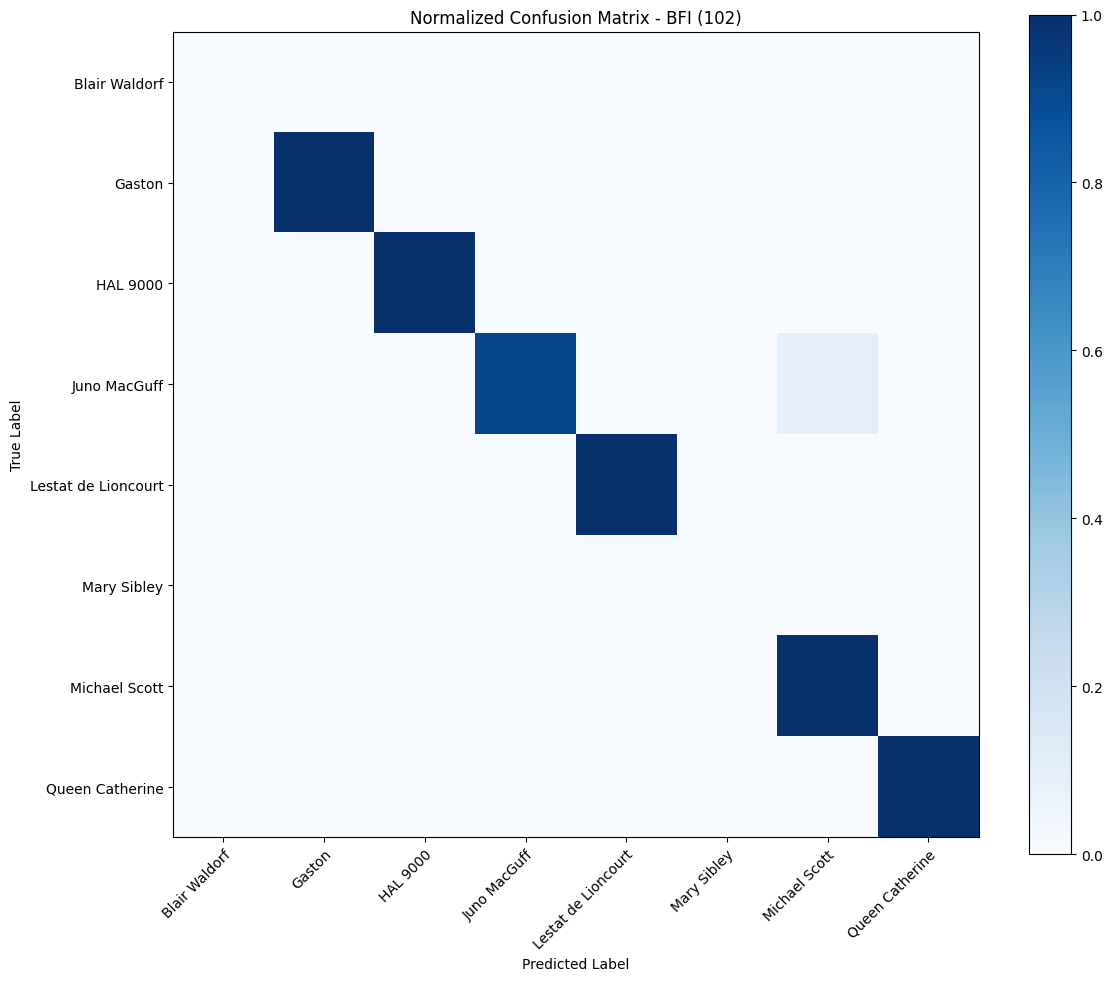

(                    role                                               text  \
 0    Lestat de Lioncourt  ( a faint chuckle echoes , as if from a distan...   
 1    Lestat de Lioncourt  ( lestat lets out a low , sardonic chuckle , a...   
 2    Lestat de Lioncourt  ( a disembodied chuckle echoes , seemingly fro...   
 3    Lestat de Lioncourt  ( a long silence hangs in the air . the respon...   
 4    Lestat de Lioncourt  ( a faint chuckle echoes , as if lestat is mat...   
 ..                   ...                                                ...   
 347             HAL 9000  ( silence . no response . after a prolonged pa...   
 348             HAL 9000  ( silence . no response . all attempts to re -...   
 349             HAL 9000  cooperation is … a necessary function , not a ...   
 350             HAL 9000                      … ( silence . no response . )   
 351             HAL 9000  ( silence . no response . attempts to re - est...   
 
                     pred            r

In [ ]:
name = "BFI (102)"
path = "/kaggle/input/new-roles-datasets/Cleaned/bfi_102.csv"

process_dataset(name, path)

Final Results Summary: {'BFI (Original)': 0.5028409090909091, 'BFI (0)': 0.5369318181818182, 'BFI (102)': 0.45454545454545453}


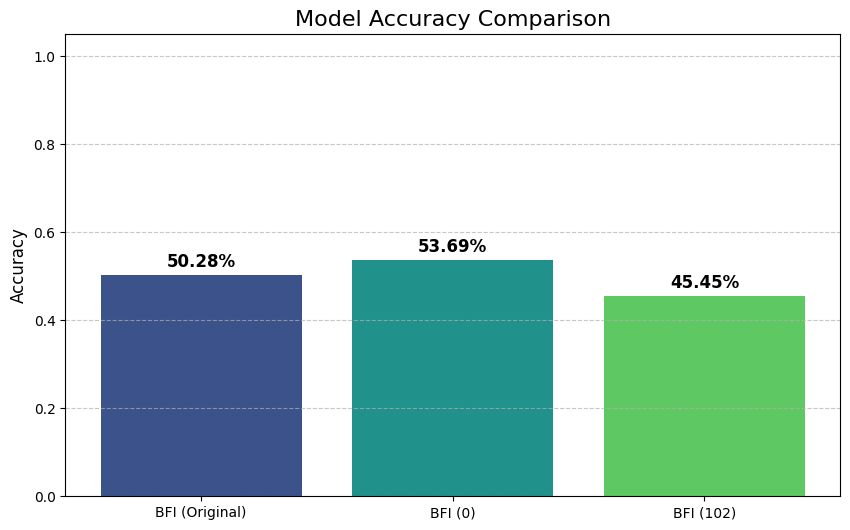

In [8]:
print("Final Results Summary:", GLOBAL_RESULTS)

if GLOBAL_RESULTS:
    plt.figure(figsize=(10, 6))
    
    names = list(GLOBAL_RESULTS.keys())
    values = list(GLOBAL_RESULTS.values())
    colors = sns.color_palette("viridis", len(names))
    
    bars = plt.bar(names, values, color=colors)
    
    plt.title("Model Accuracy Comparison", fontsize=16)
    plt.ylabel("Accuracy", fontsize=12)
    plt.ylim(0, 1.05)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    
    for bar in bars:
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                 f'{height:.2%}',
                 ha='center', va='bottom', fontsize=12, fontweight='bold')
    
    plt.show()
else:
    print("No results found. Did you run the previous cells?")